# Dólar x Real (2010–2019): uma década em três visualizações

**Disciplina:** Visualização da Informação
**Autor:** Enzo Souza
**Dataset:** `USD_BRL_hist.csv`, cotação diária do dólar em reais (2010 a 2019)

## Objetivo
Analisar a variação do dólar frente ao real ao longo de uma década usando três técnicas de visualização de unidades diferentes da disciplina:

1. **Gráfico de linhas** (informação temporal)
2. **Gráfico de barras** (estatística descritiva)
3. **Sunburst** (informação hierárquica)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cm, colors

In [2]:
# paleta de cores:
CORES_ENZO = {
    "principal": "#1f4e79",  # azul escuro: a cotação
    "alta":      "#c0392b",  # vermelho: dólar subiu
    "baixa":     "#27ae60",  # verde: dólar caiu
    "destaque":  "#f39c12",  # laranja: anotações
}

# Estilo padrão dos gráficos
plt.rcParams.update({
    "figure.figsize": (12, 6),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlesize": 14,
})

def assinatura(ax):
    """Coloca minha assinatura discreta no rodapé do gráfico."""
    ax.text(1.0, -0.12, "Visualização: Enzo | Fonte: USD_BRL_hist.csv",
            transform=ax.transAxes, ha="right", fontsize=8, color="gray")

In [3]:
df = pd.read_csv("data/USD_BRL_hist.csv", skipinitialspace=True)

# Remove espaços sobrando no início e no fim dos nomes das colunas
df.columns = df.columns.str.strip()

df.info()
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 2608 entries, 0 to 2607
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Data     2608 non-null   str    
 1   USD_BRL  2608 non-null   float64
dtypes: float64(1), str(1)
memory usage: 40.9 KB


,Data,USD_BRL
0,31.12.2019,4.0195
1,30.12.2019,4.0195
2,27.12.2019,4.0460
3,26.12.2019,4.0560
4,25.12.2019,4.0838


In [4]:
# Converte o texto "dd.mm.aaaa" para data de verdade
df["Data"] = pd.to_datetime(df["Data"], format="%d.%m.%Y")

# Ordena do mais antigo para o mais recente
df = df.sort_values("Data").reset_index(drop=True)

df.info()
display(df.head())
display(df.tail())

<class 'pandas.DataFrame'>
RangeIndex: 2608 entries, 0 to 2607
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   Data     2608 non-null   datetime64[us]
 1   USD_BRL  2608 non-null   float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 40.9 KB


,Data,USD_BRL
0,2010-01-01,1.7430
1,2010-01-04,1.7212
2,2010-01-05,1.7310
3,2010-01-06,1.7325
4,2010-01-07,1.7465


,Data,USD_BRL
2603,2019-12-25,4.0838
2604,2019-12-26,4.0560
2605,2019-12-27,4.0460
2606,2019-12-30,4.0195
2607,2019-12-31,4.0195


In [5]:
# Extrai o ano e o trimestre de cada data
df["Ano"] = df["Data"].dt.year
df["Trimestre"] = df["Data"].dt.quarter

df.head()

,Data,USD_BRL,Ano,Trimestre
0,2010-01-01,1.7430,2010,1
1,2010-01-04,1.7212,2010,1
2,2010-01-05,1.7310,2010,1
3,2010-01-06,1.7325,2010,1
4,2010-01-07,1.7465,2010,1


## Gráfico 1: Linhas (Informação temporal)

Os dados são uma **série temporal**: um valor de cotação para cada dia útil, em ordem cronológica.
O gráfico de linhas é o mais adequado porque conecta os pontos no tempo e deixa visível a
**tendência** e os **picos** da cotação ao longo da década.

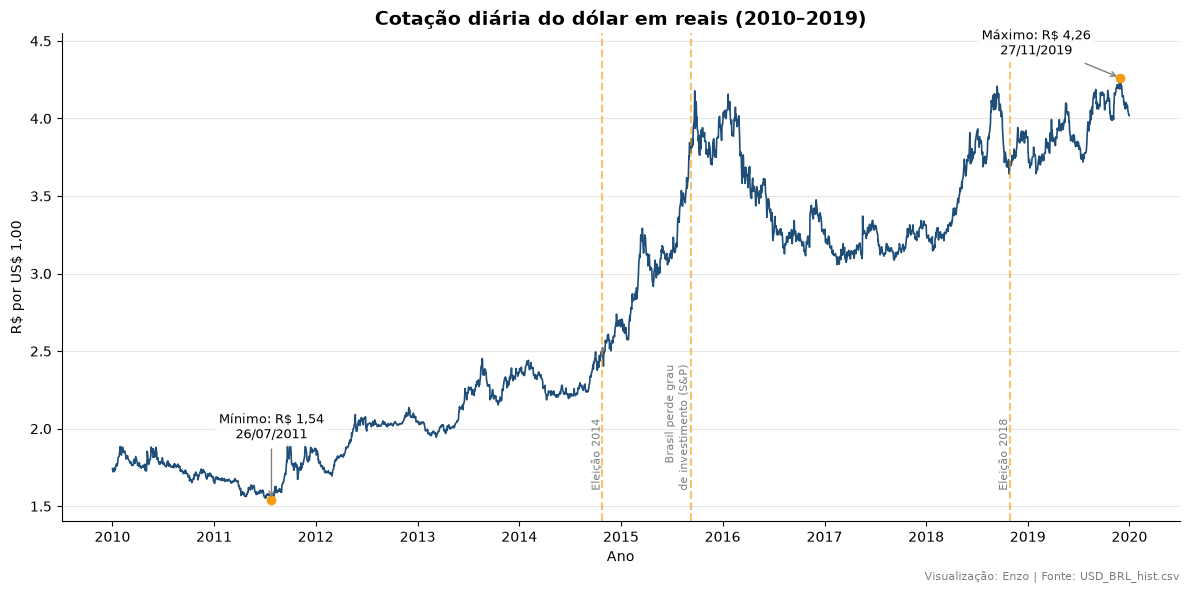

In [6]:
fig, ax = plt.subplots()

ax.plot(df["Data"], df["USD_BRL"], color=CORES_ENZO["principal"], linewidth=1.2)

# --- Mínimo e máximo, calculados a partir dos próprios dados ---
minimo = df.loc[df["USD_BRL"].idxmin()]
maximo = df.loc[df["USD_BRL"].idxmax()]

# (ponto, rótulo, deslocamento do texto em dias, deslocamento em R$)
for ponto, rotulo, dx, dy in [(minimo, "Mínimo", 0, 0.4), (maximo, "Máximo", -300, 0.15)]:
    valor = f"{ponto['USD_BRL']:.2f}".replace(".", ",")
    ax.scatter(ponto["Data"], ponto["USD_BRL"], color=CORES_ENZO["destaque"], zorder=3)
    ax.annotate(f"{rotulo}: R\\$ {valor}\n{ponto['Data']:%d/%m/%Y}",
                xy=(ponto["Data"], ponto["USD_BRL"]),
                xytext=(ponto["Data"] + pd.Timedelta(days=dx), ponto["USD_BRL"] + dy),
                ha="center", fontsize=9,
                bbox=dict(boxstyle="round", fc="white", ec="none", alpha=0.9),
                arrowprops=dict(arrowstyle="->", color="gray"))

# --- Eventos de contexto ---
eventos = {
    "2014-10-26": "Eleição 2014",
    "2015-09-09": "Brasil perde grau\nde investimento (S&P)",
    "2018-10-28": "Eleição 2018",
}
for data, nome in eventos.items():
    d = pd.Timestamp(data)
    ax.axvline(d, color=CORES_ENZO["destaque"], linestyle="--", alpha=0.6)
    ax.text(d, 1.6, nome, rotation=90, va="bottom", ha="right", fontsize=8, color="gray")

ax.set_title("Cotação diária do dólar em reais (2010–2019)")
ax.set_xlabel("Ano")
ax.set_ylabel("R\\$ por US\\$ 1,00")
ax.set_ylim(top=4.55)
ax.grid(axis="y", alpha=0.3)

assinatura(ax)
plt.tight_layout()
plt.savefig("imagens/grafico1_linhas.png", dpi=150)
plt.show()

## Gráfico 2: Barras (Estatística descritiva)

O gráfico 1 mostra **como** o dólar evoluiu. Aqui a pergunta é outra: **como cada ano se comparou?**
Os anos viram **categorias**, e a variação percentual de cada ano é comparada pelo tamanho da barra.

**Por que não pizza (setores)?** A pizza mostra partes de um todo, e as variações anuais não somam
um todo. Além disso, existem variações negativas, que a pizza não consegue representar.

In [7]:
# Primeiro e último valor de cada ano
anual = df.groupby("Ano")["USD_BRL"].agg(inicio="first", fim="last")

# Variação percentual dentro do ano
anual["Variacao_%"] = (anual["fim"] / anual["inicio"] - 1) * 100

anual.round(2)

,inicio,fim,Variacao_%
Ano,,,
2010,1.74,1.66,-4.79
2011,1.65,1.86,13.13
2012,1.87,2.05,9.50
2013,2.05,2.36,15.31
2014,2.36,2.66,12.51
2015,2.66,3.96,49.04
2016,3.96,3.25,-17.83
2017,3.29,3.31,0.82
2018,3.31,3.88,17.17


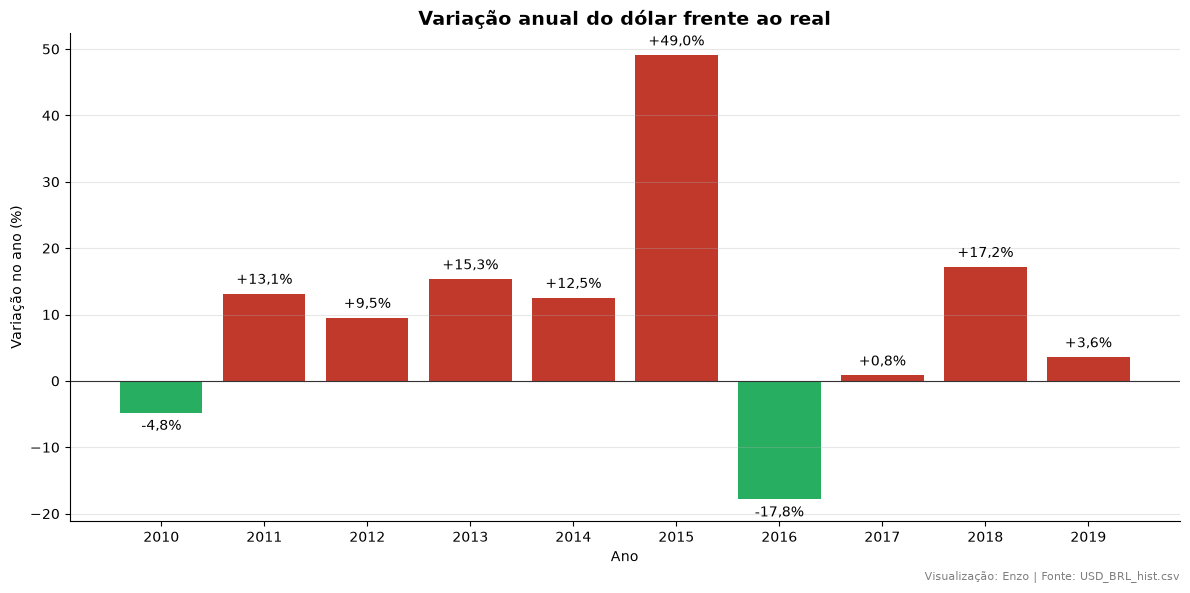

In [8]:
# Vermelho quando o dólar subiu, verde quando caiu
cores = [CORES_ENZO["alta"] if v > 0 else CORES_ENZO["baixa"] for v in anual["Variacao_%"]]

fig, ax = plt.subplots()
barras = ax.bar(anual.index.astype(str), anual["Variacao_%"], color=cores)
ax.axhline(0, color="#333333", linewidth=0.8)

# Valor escrito em cada barra
for barra, v in zip(barras, anual["Variacao_%"]):
    ax.text(barra.get_x() + barra.get_width() / 2, v + (1 if v > 0 else -1),
            f"{v:+.1f}%".replace(".", ","),
            ha="center", va="bottom" if v > 0 else "top", fontsize=10)

ax.set_title("Variação anual do dólar frente ao real")
ax.set_xlabel("Ano")
ax.set_ylabel("Variação no ano (%)")
ax.grid(axis="y", alpha=0.3)

assinatura(ax)
plt.tight_layout()
plt.savefig("imagens/grafico2_barras.png", dpi=150)
plt.show()

## Gráfico 3: Sunburst (Informação hierárquica)

A data tem uma **hierarquia natural**: cada ano se divide em quatro trimestres.
O sunburst representa essa hierarquia em anéis: o **anel interno** são os anos e o **anel externo**
são os trimestres de cada ano. A **cor** mostra a cotação média do período: quanto mais escuro,
mais caro estava o dólar.

O tamanho de cada fatia é proporcional ao número de dias úteis, por isso as fatias são quase
iguais. Isso é intencional: cada fatia representa um pedaço do tempo, e a informação está na cor.

In [9]:
# Nível 1 da hierarquia: média por ano
media_ano = df.groupby("Ano")["USD_BRL"].mean()

# Nível 2 da hierarquia: média e quantidade de dias por ano + trimestre
tri = (df.groupby(["Ano", "Trimestre"])["USD_BRL"]
         .agg(media="mean", dias="count")
         .reset_index())

# Total de dias úteis de cada ano (tamanho das fatias do anel interno)
dias_ano = tri.groupby("Ano")["dias"].sum()

tri.head(8).round(2)

,Ano,Trimestre,media,dias
0,2010,1,1.80,64
1,2010,2,1.79,65
2,2010,3,1.75,66
3,2010,4,1.70,66
4,2011,1,1.67,64
5,2011,2,1.59,65
6,2011,3,1.64,66
7,2011,4,1.80,65


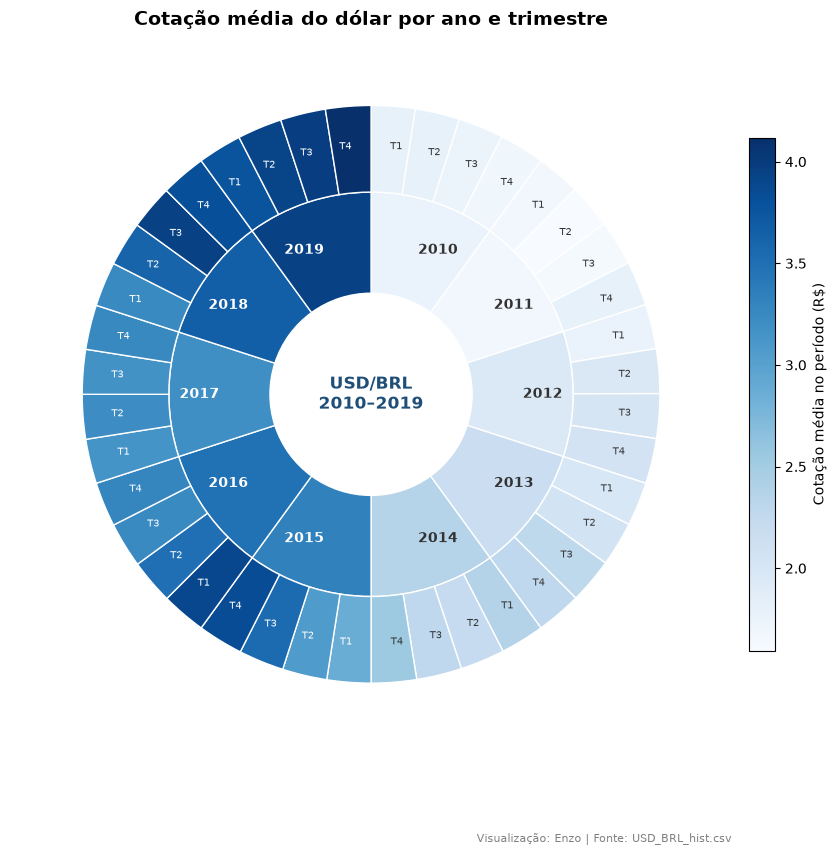

In [10]:
# A mesma escala de cor para os dois anéis, para que sejam comparáveis
norma = colors.Normalize(vmin=tri["media"].min(), vmax=tri["media"].max())
mapa = plt.get_cmap("Blues")

def cor_do_texto(valor):
    """Texto branco em fatia escura e texto escuro em fatia clara."""
    return "white" if norma(valor) > 0.5 else "#333333"

fig, ax = plt.subplots(figsize=(9, 9))

# Anel interno: anos
_, textos_ano = ax.pie(dias_ano, radius=0.7, colors=mapa(norma(media_ano.values)),
                       labels=dias_ano.index, labeldistance=0.75,
                       textprops=dict(fontsize=10, fontweight="bold"),
                       wedgeprops=dict(width=0.35, edgecolor="white"),
                       startangle=90, counterclock=False)

# Anel externo: trimestres
_, textos_tri = ax.pie(tri["dias"], radius=1.0, colors=mapa(norma(tri["media"].values)),
                       labels=[f"T{t}" for t in tri["Trimestre"]], labeldistance=0.86,
                       textprops=dict(fontsize=7),
                       wedgeprops=dict(width=0.3, edgecolor="white"),
                       startangle=90, counterclock=False)

# Ajusta a cor de cada rótulo conforme o fundo
for texto, valor in zip(textos_ano, media_ano.values):
    texto.set_color(cor_do_texto(valor))
for texto, valor in zip(textos_tri, tri["media"].values):
    texto.set_color(cor_do_texto(valor))

ax.text(0, 0, "USD/BRL\n2010–2019", ha="center", va="center",
        fontsize=12, fontweight="bold", color=CORES_ENZO["principal"])

barra_cor = fig.colorbar(cm.ScalarMappable(norm=norma, cmap=mapa), ax=ax, shrink=0.6, pad=0.02)
barra_cor.set_label("Cotação média no período (R$)")

ax.set_title("Cotação média do dólar por ano e trimestre")
assinatura(ax)
plt.tight_layout()
plt.savefig("imagens/grafico3_sunburst.png", dpi=150)
plt.show()